# LASSO (L1-Regularized Linear Regression) — Summary for Presentation

## 1. What LASSO Solves
LASSO estimates coefficients $w$ by minimizing the objective

$$
\frac{1}{2n}\|y - Xw\|^2_2 + \alpha \|w\|_1,
$$

where  
- $X$ = data matrix,  
- $y$ = target,  
- $w$ = coefficients,  
- $\alpha$ = regularization strength.

The $L1$ penalty $\|w\|_1$ encourages **sparsity**: many coefficients become exactly zero.

---

## 2. Why LASSO Matters for SINDy
In the SINDy algorithm, we learn a sparse model  
$$\dot{X} = \Theta(X)\Xi,$$  
where $\Theta(X)$ is the feature library (polynomials, etc.) and $\Xi$ contains coefficients.  

Applying LASSO to each column of the target $\dot{X}$ helps:
- **select the important features** (nonzero rows of $\Xi$),
- **eliminate unnecessary terms** automatically,
- **avoid overfitting** when the library is large.

---

## 3. Intuition: How LASSO Shrinks Coefficients
- Ordinary least squares gives  
$$w = \arg\min \|y - Xw\|_2^2.$$

- LASSO adds a penalty for large coefficient magnitudes.  
- The $L1$ norm has a **sharp corner at 0**, making it likely that some $w_i = 0$.

The geometric picture: the optimal solution is "pushed" onto coordinate axes, producing sparsity.

---

## 4. The `alpha` Parameter
- Larger $\alpha$ ⇒ stronger shrinkage ⇒ **more zeros**.  
- $\alpha = 0$ recovers ordinary least squares (not recommended in `Lasso`).  
- In practice, $\alpha$ is tuned with cross-validation (`LassoCV`).

---

## 5. Important Parameters in `sklearn.linear_model.Lasso`

- **alpha**: strength of the L1 penalty.  
- **fit_intercept**: whether to learn an intercept.  
- **max_iter**: maximum optimization iterations.  
- **tol**: convergence tolerance.  
- **selection**:  
  - `'cyclic'` updates coefficients in order,  
  - `'random'` selects coefficients randomly (often faster).

Optimization is performed with **coordinate descent**, updating one coefficient at a time.

---

## 6. Attributes Available After Fitting
- **coef_**: learned coefficients $w$.  
- **intercept_**: learned intercept term.  
- **n_iter_**: iterations required for convergence.  
- **dual_gap_**: measures solution optimality.  

---

## 7. Simple Example (1D Toy Problem)
Suppose the true model is

$$y = 3x + \epsilon,$$

but we give the model a large feature library.  
LASSO will recover something like

- coefficient on $x$: $\approx 3$  
- coefficients on irrelevant features: $0$

while ordinary least squares typically produces small nonzero noise everywhere.

---

## 8. When LASSO Works Best in SINDy
- When the true system has **few active terms**,  
- When the library $\Theta(X)$ is **large**,  
- When data are noisy and we need **robust feature selection**.

For multi-output dynamics, apply LASSO **column-wise**:
- one model for $d x_i / dt$ for each state variable.

(Later we may replace this by MultiTaskLasso to enforce shared sparsity.)

---

## 9. Relation to Elastic Net
LASSO is a special case of Elastic Net:

$$
\text{ElasticNet} = \frac{1}{2n}\|y - Xw\|_2^2
+ \alpha \left( l1\_ratio \|w\|_1 + (1 - l1\_ratio)\|w\|_2^2 \right)
$$

Setting $l1\_ratio = 1$ produces **pure LASSO**.

---

## 10. Summary
- LASSO solves a sparse regression problem using an $L1$ penalty.  
- It is essential to SINDy for selecting active terms.  
- Key hyperparameter: $\alpha$.  
- Solver uses coordinate descent.  
- Produces interpretable, efficient dynamical models.


In [ ]:
import numpy as np
from sklearn.linear_model import Lasso

# Fake training data
x = np.linspace(-2, 2, 200) # Dr. Forbes' class
xdot_true = 3*x - 2*x**3 + 0.1*np.random.randn(len(x))    # adding noise, Dr. Forbes

# print(x[:5])
# print(xdot_true[:5])
# print(np.ones(x)) # array of ones with inputed size
# print(np.ones_like(x)) # array of ones with same type and shape as inputed
# print([np.ones_like(x), x, x**2, x**3][:5])

Theta = np.column_stack([np.ones_like(x), x, x**2, x**3])
# print(Theta)


# creating lasso object with (1 / (2 * n_samples)) * ||y - Xw||^2_2 + alpha * ||w||_1
lasso = Lasso(alpha=0.05)
lasso.fit(Theta, xdot_true) # fit (x_dot_true-Theta*ksi)

print("Coefficients:", lasso.coef_)
print("Intercept:", lasso.intercept_)
print("Number of iterations:", lasso.n_iter_)
print("Dual gap:", lasso.dual_gap_)

Coefficients: [ 0.          2.69475719  0.         -1.89222828]
Intercept: 0.005240749723538647
Number of iterations: 48
Dual gap: 0.00048495023796331084


In [ ]:
# Understanding numpy for myself
import numpy as np

# Create a 1D array of 5 ones
ones_1d = np.ones(5)
print("1D array of 5 ones:")
print(ones_1d)

# Create a 2x3 array of ones
ones_2d = np.ones((2, 3))
print("\n2x3 array of ones:")
print(ones_2d)

# Create a 3x2x4 array of ones with float data type
ones_3d = np.ones((3, 2, 4), dtype=float)
print("\n3x2x4 array of ones with float type:")
print(ones_3d)

# Create an array of ones with the same shape as an existing array
existing_array = np.array([[1, 2], [3, 4]])
ones_like_existing = np.ones_like(existing_array)
print("\nArray of ones with the same shape as existing_array:")
print(ones_like_existing)

1D array of 5 ones:
[1. 1. 1. 1. 1.]

2x3 array of ones:
[[1. 1. 1.]
 [1. 1. 1.]]

3x2x4 array of ones with float type:
[[[1. 1. 1. 1.]
  [1. 1. 1. 1.]]

 [[1. 1. 1. 1.]
  [1. 1. 1. 1.]]

 [[1. 1. 1. 1.]
  [1. 1. 1. 1.]]]

Array of ones with the same shape as existing_array:
[[1 1]
 [1 1]]


# MultiTaskLasso — Summary (Colab Markdown from scikit-learn)

## 1. What MultiTaskLasso Solves
MultiTaskLasso solves the optimization problem

$$
\frac{1}{2n} \|Y - XW\|_{\mathrm{Fro}}^2
+ \alpha \|W\|_{21},
$$

where  
- $X$ = data matrix,  
- $Y$ = matrix of multiple target outputs,  
- $W$ = coefficient matrix,  
- $\|W\|_{\mathrm{Fro}}$ = Frobenius norm,  
- $\|W\|_{21} = \sum_i \sqrt{\sum_j w_{ij}^2}$ = *row-wise mixed norm*.

The $L1/L2$ mixed penalty enforces **row sparsity**: entire rows of $W$ become zero together.

This means:  
**if a feature is irrelevant for one task, it is eliminated for *all* tasks simultaneously.**

---

## 2. Why MultiTaskLasso Matters (vs. Lasso)
In SINDy or any multi-output regression:

- Lasso treats each output equation separately.  
- MultiTaskLasso enforces **shared sparsity** across outputs.

This is crucial when modeling multivariate dynamics:

$$
\dot{X} = \Theta(X) W,
$$

because the same terms often appear across the equations for $x$, $y$, $z$, etc.

**MultiTaskLasso ensures that feature selection is consistent across all state variables.**

---

## 3. Intuition Behind the Mixed Norm
- Standard Lasso penalizes each coefficient individually (elementwise sparsity).  
- MultiTaskLasso penalizes the **Euclidean norm of each row** of $W$.

Geometric effect:  
if a feature (a row of $W$) is small across all tasks, the mixed $L1/L2$ norm pushes the **entire row to zero at once**.

This leads to:
- cleaner, more interpretable models,  
- stability when outputs are correlated,  
- fewer spurious features.

---

## 4. Formal Definition of the Row-Sparsity Penalty
The mixed norm is

$$
\|W\|_{21} = \sum_{i=1}^{n_{\text{features}}} \sqrt{
w_{i1}^2 + w_{i2}^2 + \cdots + w_{i\,n_{\text{targets}}}^2
}.
$$

If the norm of row $i$ is small, MultiTaskLasso removes the **entire row**.

This is the core mechanism enforcing **shared feature selection**.

---

## 5. Important Parameters (with Interpretation)

- **alpha**  
  Controls the strength of row-sparsity.  
  Larger $\alpha$ ⇒ fewer active features.

- **fit_intercept**  
  Whether to include independent offsets.

- **max_iter**  
  Coordinate-descent iteration cap.

- **tol**  
  Convergence tolerance; smaller = more accurate.

- **selection** (`'cyclic'` or `'random'`)  
  `'random'` often converges faster.

- **warm_start**  
  Reuse previous solution (helpful when sweeping alphas).

---

## 6. After Fitting: Key Attributes

- **coef_**  
  Shape: `(n_targets, n_features)`  
  The transpose of $W$.

- **intercept_**  
  One intercept per target.

- **n_iter_**  
  Iterations used by the coordinate descent solver.

- **dual_gap_**  
  Optimization optimality certificate.

- **sparse_coef_**  
  Sparse representation of the coefficient matrix.

---

## 7. Example: Why MultiTaskLasso Helps in SINDy
Suppose your library $\Theta(X)$ contains polynomial terms.  
For Lorenz-type systems, the same nonlinear terms often appear in multiple equations.

**Lasso (per equation):**  
- selects features independently for $\dot{x}$, $\dot{y}$, $\dot{z}$.  
- may produce inconsistent sparsity (e.g., nonlinear term appears in one equation but not another).

**MultiTaskLasso:**  
- selects terms jointly across the three equations,  
- ensuring the model remains structurally consistent.

---

## 8. Toy Example (Very Simple Illustration)

Training data:

- Two tasks (two outputs)  
- Two features

MultiTaskLasso might yield:

$$
W =
\begin{bmatrix}
0 & 0.61 \\
0 & 0.95
\end{bmatrix},
$$

Meaning:  
- Feature 1 is irrelevant for *both* tasks.  
- Feature 2 is active for both tasks.  

Lasso could have incorrectly kept feature 1 for one task and removed it for another.

---

## 9. Coordinate Descent (How It Works Under the Hood)
MultiTaskLasso uses **block coordinate descent**(I should further read it in Optim 565 notes):

1. Pick one feature row of $W$.  
2. Update the vector  $   W_{i,:}  $   across all tasks simultaneously.  
3. Apply soft-thresholding to the vector norm.  
4. Repeat until convergence.

This block update is what makes row-sparsity possible.

---

## 10. Summary (Slide-Ready Bullets)

- MultiTaskLasso solves joint regression problems with shared sparsity.  
- Uses mixed $L1/L2$ penalty: encourages entire rows of $W$ to become zero.  
- Ideal for **multi-output dynamical systems** like SINDy.  
- Produces consistent feature selection across tasks.  
- Optimized via block coordinate descent.  
- More stable and interpretable than independent Lasso fits.

# Lasso vs MultiTaskLasso (SINDy)

| Method | Sparsity Type | How It Works | Pros | Cons |
|-------|---------------|--------------|------|------|
| **Lasso** | Column-wise sparsity | Fits each equation independently | Simple; fast | Equations may select inconsistent features |
| **MultiTaskLasso** | **Row-wise shared sparsity** | Fits all equations jointly with mixed $L1/L2$ penalty | Consistent feature selection; better for coupled dynamics | Slightly slower |

### Why MultiTaskLasso Is Better for SINDy
- Dynamical systems share the same nonlinear terms across equations  
- Row-sparsity enforces structural consistency  
- Produces cleaner, more interpretable models  


Identified coefficients (MultiTaskLasso):


,dx/dt,dy/dt
1,0.000000,0.000000
x,2.730577,-1.830098
x^2,0.000000,-0.000000
x^3,-1.902971,0.939954


Intercepts (two tasks): [-0.0079949  -0.00654902]
Number of iterations: 47
Dual gap: 0.0007268076670965584


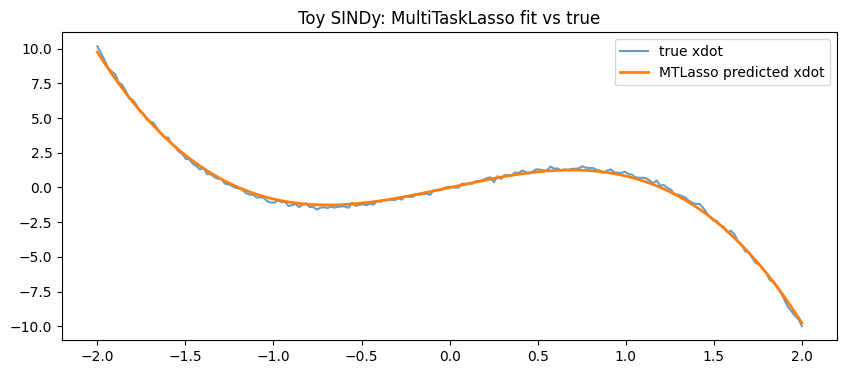

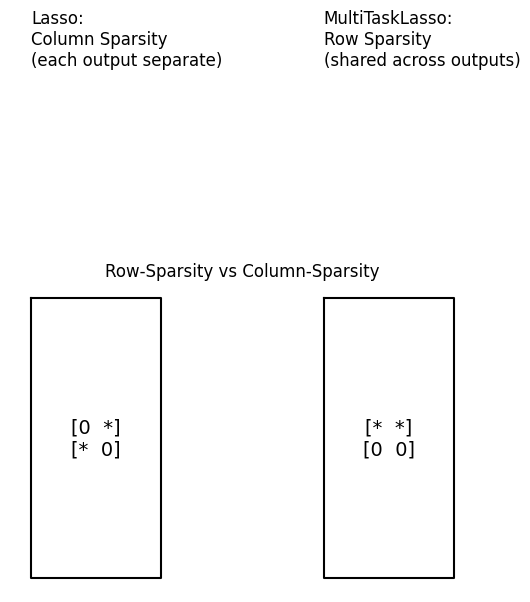

In [ ]:
# ======================================================
# MultiTaskLasso on the toy SINDy problem (example above in the lasso)
# ======================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import MultiTaskLasso

# ------------------------------------------------------
# 1. Generate simple 1D data (we extend it to 2 outputs)
# ------------------------------------------------------
x = np.linspace(-2, 2, 200)

# True model:
#   ẋ = 3 x − 2 x^3 + noise
xdot_true = 3*x - 2*(x**3) + 0.1*np.random.randn(len(x))

# We create a FAKE second output to enable MultiTaskLasso:
#   ẏ = -2 x + x^3 + noise
ydot_true = -2*x + (x**3) + 0.1*np.random.randn(len(x))

# Stack outputs into (n_samples × 2) matrix required by MultiTaskLasso
Xdot = np.column_stack([xdot_true, ydot_true])

# ------------------------------------------------------
# 2. Build the SINDy library Θ(x)
# ------------------------------------------------------
Theta = np.column_stack([
    np.ones_like(x),
    x,
    x**2,
    x**3
])
feature_names = ['1', 'x', 'x^2', 'x^3']

# ------------------------------------------------------
# 3. Fit MultiTaskLasso
# ------------------------------------------------------
mtlasso = MultiTaskLasso(alpha=0.05)
mtlasso.fit(Theta, Xdot)

Xi = mtlasso.coef_.T        # shape (features × 2)
intercept = mtlasso.intercept_

# ------------------------------------------------------
# 4. Print results
# ------------------------------------------------------
import pandas as pd

df = pd.DataFrame(
    Xi,
    index=feature_names,
    columns=['dx/dt', 'dy/dt']
)

print("Identified coefficients (MultiTaskLasso):")
display(df)

print("Intercepts (two tasks):", intercept)
print("Number of iterations:", mtlasso.n_iter_)
print("Dual gap:", mtlasso.dual_gap_)

# ------------------------------------------------------
# 5. Plot original vs. learned derivative (for dx/dt only)
# ------------------------------------------------------
xdot_learned = Theta @ Xi[:, 0] + intercept[0]

plt.figure(figsize=(10, 4))
plt.plot(x, xdot_true, label="true xdot", alpha=0.7)
plt.plot(x, xdot_learned, label="MTLasso predicted xdot", linewidth=2)
plt.title("Toy SINDy: MultiTaskLasso fit vs true")
plt.legend()
plt.show()

# ------------------------------------------------------
# 6. Row-sparsity vs Column-sparsity visual diagram
# ------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 4))

ax.text(0.1, 0.8, "Lasso:\nColumn Sparsity\n(each output separate)", fontsize=12)
ax.text(0.55, 0.8, "MultiTaskLasso:\nRow Sparsity\n(shared across outputs)", fontsize=12)

# Draw Lasso (column sparsity) matrix
ax.plot([0.1, 0.3, 0.3, 0.1, 0.1], [0.55, 0.55, 0.25, 0.25, 0.55], 'k')
ax.text(0.2, 0.4, "[0  *]\n[*  0]", ha='center', va='center', fontsize=14)

# Draw MTLasso (row sparsity) matrix
ax.plot([0.55, 0.75, 0.75, 0.55, 0.55], [0.55, 0.55, 0.25, 0.25, 0.55], 'k')
ax.text(0.65, 0.4, "[*  *]\n[0  0]", ha='center', va='center', fontsize=14)

ax.set_axis_off()
plt.title("Row-Sparsity vs Column-Sparsity")
plt.show()